# 01 · Quickstart: two particles in one cavity

This notebook builds a two-particle coherent-scattering system from physical parameters, inspects
it, and calculates its optical (homodyne, heterodyne) and mechanical (position) spectra. It then
identifies the peaks as the normal modes of the drift matrix, measures the optical spring shift,
and checks whether the system has a steady state at all.

**Runtime:** about 5 s. **Background:** [Getting started](../../docs/getting_started.md),
[Spectra of several particles in one cavity](../../docs/guide/cavity_spectra.md) and
[Conventions](../../docs/concepts/conventions.md) (units, Fourier convention, spectral
normalisation).

Run it from a clone of the repository with `pip install -e .`, or with `PYTHONPATH` pointing at the
repository root.

In [1]:
import os
os.environ.setdefault('TQDM_DISABLE', '1')  # hide the progress bar each levisim spectrum call shows

import numpy as np
import matplotlib.pyplot as plt

from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import kHz, Hz
from levisim.multiphysics.covariance import steady_state_covariance, dimension_covariance
from levisim.analysis.gaussian_states import mean_phonon_numbers
from levisim.multiphysics.enums import QuantumLinearTheoryMethod
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.utils.shelf import DEFAULT_cavity_kwargs, DEFAULT_gas_kwargs

set_plt_rcParams_to_xmgrace_style()
LAM = QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL

## 1. Build the system

With no `toy_params`, `MultiTrap` builds each particle from the physics: a silica bead (radius
about 60 nm) in its own 1064 nm tweezer, at a node of the cavity standing wave. The trap
frequencies follow from the tweezer waist and power, and the coherent-scattering couplings $g_{j_n}$
from the bead's polarisability and the overlap of the tweezer and cavity fields. The second tweezer
has optical phase $\phi_2 = 90^\circ$ relative to the first.

`ω_range` can be a list of grids, which `MultiTrap` stitches together: here a coarse grid over
$\pm 170$ kHz and fine grids (10 Hz steps) around the mechanical peaks at positive and negative
frequency. Remember that frequencies are angular: `kHz` is $2\pi \times 10^3$ rad/s.

In [2]:
ω_range = [
    np.arange(-170, 170, 0.5) * kHz,     # background
    np.arange(125, 165, 0.01) * kHz,     # mechanical peaks, anti-Stokes side
    np.arange(-165, -125, 0.01) * kHz,   # mechanical peaks, Stokes side
]
mtrap = MultiTrap(
    num_traps=2,
    Cartesian_axes_per_trap=2,              # x and y of each particle
    gas_kwargs=DEFAULT_gas_kwargs,          # 1e-6 mbar, 300 K
    cavity_kwargs=DEFAULT_cavity_kwargs,    # Δ = -2π × 450 kHz, L = 0.96 cm, finesse 40 000
    ω_range=ω_range,
)
cavity = mtrap.cavity
print(f'{mtrap}: {len(mtrap.ω_range)} frequency points')
print(f'cavity: κ/2π = {cavity.κ / kHz:.1f} kHz, Δ/2π = {cavity.Δ / kHz:.1f} kHz, θhom = {np.degrees(cavity.θhom):.0f}°\n')
print('motion   Ω/2π (kHz)   g/2π (kHz)   φ (deg)   n_th          Γ/2π (mHz)   Γ_opt/2π (kHz)')
for label, dim in mtrap.dimensions.items():
    print(
        f'{label:>6}   {dim.Ω / kHz:10.3f}   {dim.g / kHz:10.3f}   {np.degrees(dim.φ):7.1f}'
        f'   {dim.noise_phonons_exact:.3e}   {dim.Γ / Hz * 1e3:10.3f}   {dim.cooling_rate / kHz:14.3f}'
    )

MultiTrap(2×2): 8678 frequency points
cavity: κ/2π = 390.4 kHz, Δ/2π = -450.0 kHz, θhom = 45°

motion   Ω/2π (kHz)   g/2π (kHz)   φ (deg)   n_th          Γ/2π (mHz)   Γ_opt/2π (kHz)
    x1      156.338      -22.237       0.0   3.998e+07        1.155            1.077
    y1      135.798      -23.859       0.0   4.603e+07        1.155            1.041
    x2      152.121      -22.521      90.0   4.109e+07        1.153            1.067
    y2      137.634      -23.676      90.0   4.542e+07        1.153            1.042


`Γ` is the gas damping, $n_\text{th}$ the thermal occupation of the bath at 300 K, and
`cooling_rate` ($\Gamma_\text{opt}$) the textbook weak-coupling optical damping each motion would get
if it were alone in the cavity. `mtrap.info`, `mtrap.info_per_trap` and `mtrap.info_per_dimension`
print everything else (masses, zero-point fluctuations, cavity field, ...).

## 2. Optical spectra

The homodyne spectrum is the spectrum of the output-light quadrature at angle `cavity.θhom`, and
the heterodyne spectrum that of $\hat a_\text{out}$ itself. Both are in shot-noise units, so far
from any mechanical feature they tend to 1.

🧮 Calculating homodyne spectrum with method=LAM
⏱️ Function "homodyne_spectrum" executed in 2.2760 seconds
🧮 Calculating heterodyne spectrum with method=LAM
⏱️ Function "heterodyne_spectrum" executed in 1.8498 seconds
at ω = 0: S_hh = 1.0374, S_het = 1.0188 (shot noise = 1)
largest anti-Stokes peak 903 at 154.45 kHz; largest Stokes peak 565 at -134.91 kHz


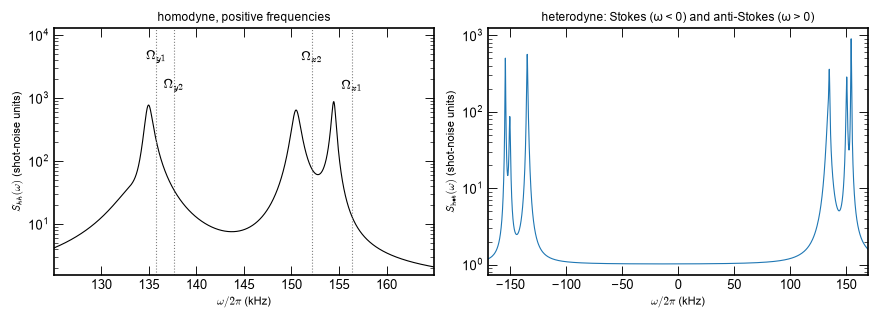

In [3]:
S_hh = mtrap.homodyne_spectrum(LAM)
S_het = mtrap.heterodyne_spectrum(LAM)

f = mtrap.ω_range / kHz          # ordinary frequency in kHz, for plotting
band = (f > 125) & (f < 165)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.semilogy(f[band], S_hh[band], color='k')
for ii, (label, dim) in enumerate(sorted(mtrap.dimensions.items(), key=lambda item: item[1].Ω)):
    ax1.axvline(dim.Ω / kHz, ls=':', lw=1, color='grey')
    ax1.text(dim.Ω / kHz, (1.4 if ii % 2 else 4) * S_hh[band].max(), f'$\\Omega_{{{label[0]}{label[1:]}}}$',
             ha='center', va='bottom', fontsize=12)
ax1.set_ylim(top=15 * S_hh[band].max())
ax1.set_xlim(f[band][0], f[band][-1])
ax1.set_xlabel(r'$\omega / 2\pi$ (kHz)')
ax1.set_ylabel(r'$S_{hh}(\omega)$ (shot-noise units)')
ax1.set_title('homodyne, positive frequencies', fontsize=11)

ax2.semilogy(f, S_het, color='tab:blue')
ax2.set_xlim(f[0], f[-1])
ax2.set_xlabel(r'$\omega / 2\pi$ (kHz)')
ax2.set_ylabel(r'$S_\mathrm{het}(\omega)$ (shot-noise units)')
ax2.set_title('heterodyne: Stokes (ω < 0) and anti-Stokes (ω > 0)', fontsize=11)
fig.tight_layout()

far = np.argmin(np.abs(f))
print(f'at ω = 0: S_hh = {S_hh[far]:.4f}, S_het = {S_het[far]:.4f} (shot noise = 1)')
print(f'largest anti-Stokes peak {S_het[f > 0].max():.0f} at {f[f > 0][np.argmax(S_het[f > 0])]:.2f} kHz;'
      f' largest Stokes peak {S_het[f < 0].max():.0f} at {f[f < 0][np.argmax(S_het[f < 0])]:.2f} kHz')

The dotted lines are the bare trap frequencies. Every peak sits *below* its bare frequency: that is
the optical spring of a red-detuned cavity (section 4). In the heterodyne spectrum the
anti-Stokes sidebands ($\omega > 0$, photons scattered up towards the cavity resonance, which removes
phonons) are mostly larger than the Stokes ones, as expected for cooling - but the largest Stokes
peak, near $-135$ kHz, is not. Section 5 explains why.

## 3. Position spectra

`all_position_power_spectra` returns the power spectral density of every dimensionless position
$\hat q_{j_n} = \hat b_{j_n} + \hat b_{j_n}^\dagger$ (in units of its zero-point fluctuation; pass
`zpf_scaled=False` for m²/Hz-type units), as an array and as a dict keyed by label.

🧮 Calculating all position PSDs with method=LAM (zpf_scaled=True)
⏱️ Function "all_position_power_spectra" executed in 5.2281 seconds
x1: peak at 154.45 kHz
y1: peak at 134.85 kHz
x2: peak at 150.47 kHz
y2: peak at 134.93 kHz


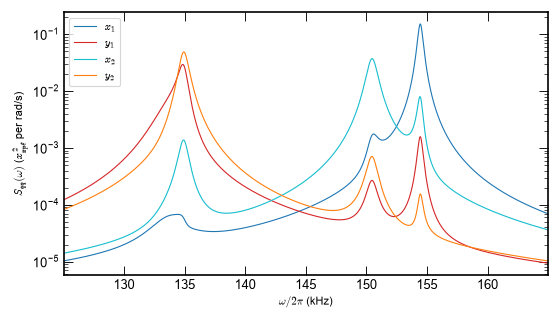

In [4]:
psd_array, psd = mtrap.all_position_power_spectra(LAM)

fig, ax = plt.subplots(figsize=(7, 4))
colours = dict(x1='tab:blue', x2='tab:cyan', y1='tab:red', y2='tab:orange')
for label, S in psd.items():
    ax.semilogy(f[band], S[band], color=colours[label], label=f'${label[0]}_{label[1:]}$')
ax.set_xlim(f[band][0], f[band][-1])
ax.set_xlabel(r'$\omega / 2\pi$ (kHz)')
ax.set_ylabel(r'$S_{qq}(\omega)$ ($x_\mathrm{zpf}^2$ per rad/s)')
ax.legend(fontsize=10, loc='upper left')
fig.tight_layout()
for label, S in psd.items():
    print(f'{label}: peak at {f[band][np.argmax(S[band])]:.2f} kHz')

Each $x$ motion has its own peak (plus a small copy of the other particle's), but $y_1$ and $y_2$,
whose bare frequencies are 1.8 kHz apart, peak at the *same* frequency, 134.9 kHz, with a broad
shoulder near 133.8 kHz: the cavity has hybridised them into collective modes. To see what the
peaks are, look at the normal modes.

## 4. Normal modes and the optical spring

The quantum Langevin equations are $\dot{\hat{\mathbf c}} = \mathbf A \hat{\mathbf c} + \hat{\mathbf c}_\text{in}$
(`mtrap.drift_matrix`). Each eigenvalue $\lambda_k = -i\Omega_k - \gamma_k/2$ of $\mathbf A$ is a
normal mode with frequency $\Omega_k$ and energy damping rate $\gamma_k$, and the size of each
eigenvector's components on $\hat b_{j_n}$, $\hat b_{j_n}^\dagger$ tells which motions take part in it.

In [5]:
λ, vectors = np.linalg.eig(mtrap.drift_matrix)
order = np.argsort(λ.imag)                    # Im λ = -Ω: positive-frequency modes first
print(' Ω_k/2π (kHz)   γ_k/2π (kHz)   weight on  x1    y1    x2    y2')
normal_modes = []
for k in order:
    Ω_k, γ_k = -λ[k].imag, -2 * λ[k].real
    if not 0 < Ω_k < 300 * kHz:               # skip the cavity-like modes and the ω < 0 copies
        continue
    v = np.abs(vectors[:, k])**2
    weights = np.array([v[i] + v[i + 1] for i in range(2, mtrap.num_operators, 2)])
    weights /= weights.sum()
    normal_modes.append((Ω_k, γ_k))
    print(f'{Ω_k / kHz:13.3f}   {γ_k / kHz:12.4f}   ' + '  '.join(f'{w:4.2f}' for w in weights))

 Ω_k/2π (kHz)   γ_k/2π (kHz)   weight on  x1    y1    x2    y2
      154.450         0.4670   0.94  0.01  0.04  0.00
      150.467         0.9614   0.04  0.01  0.94  0.02
      134.922        -0.8523   0.00  0.39  0.01  0.59
      133.752         3.6004   0.01  0.60  0.02  0.37


The $x$ normal modes are almost pure single-particle motions, shifted down by about 1.9 and
1.7 kHz from their bare frequencies; the two $y$ modes are near-equal mixtures of $y_1$ and $y_2$.

For a single motion, the weak-coupling optical spring and optical damping are

$$
\delta\Omega = |G|^2\left[\frac{\Delta + \Omega}{(\Delta + \Omega)^2 + \kappa^2/4} + \frac{\Delta - \Omega}{(\Delta - \Omega)^2 + \kappa^2/4}\right],
\qquad
\Gamma_\text{opt} = |G|^2\kappa\left[\frac{1}{(\Delta + \Omega)^2 + \kappa^2/4} - \frac{1}{(\Delta - \Omega)^2 + \kappa^2/4}\right],
$$

with levisim's $\Delta = \omega_\text{tw} - \omega_\text{c} < 0$ for red detuning. Check them against the
exact normal mode of particle 1's $x$ motion alone in the cavity:

In [6]:
single = MultiTrap(num_traps=1, Cartesian_axes_per_trap=1, gas_kwargs=DEFAULT_gas_kwargs,
                   cavity_kwargs=DEFAULT_cavity_kwargs, ω_range=np.array([0.0]))
dim = single.dimensions['x1']
Δ, κ, Ω, G2 = single.cavity.Δ, single.cavity.κ, dim.Ω, abs(dim.G)**2
δΩ_formula = G2 * ((Δ + Ω) / ((Δ + Ω)**2 + κ**2 / 4) + (Δ - Ω) / ((Δ - Ω)**2 + κ**2 / 4))
Γ_formula = G2 * κ * (1 / ((Δ + Ω)**2 + κ**2 / 4) - 1 / ((Δ - Ω)**2 + κ**2 / 4))

λ1 = np.linalg.eigvals(single.drift_matrix)
λ1 = λ1[np.argmin(np.abs(λ1.imag + Ω))]      # the mechanical eigenvalue at +Ω
print(f'optical spring  δΩ/2π: formula {δΩ_formula / kHz:+.4f} kHz, exact {(-λ1.imag - Ω) / kHz:+.4f} kHz')
print(f'optical damping Γ/2π : formula {Γ_formula / kHz:.4f} kHz (= Dimension.cooling_rate {dim.cooling_rate / kHz:.4f}),'
      f' exact {-2 * λ1.real / kHz:.4f} kHz')

optical spring  δΩ/2π: formula -1.9068 kHz, exact -1.9190 kHz
optical damping Γ/2π : formula 1.0767 kHz (= Dimension.cooling_rate 1.0767), exact 1.0726 kHz


The weak-coupling formulas are within about 0.6% of the exact eigenvalue, which includes the
coupling to all orders. In the two-particle system the $x_1$ mode is shifted by a further few tens
of Hz by the other particle, and the $y$ modes much more, because $y_1$ and $y_2$ are closer together
than their optical damping allows the cavity to resolve.

## 5. A check worth making: is there a steady state?

The table in section 4 has one normal mode, near 134.9 kHz, with **negative** damping: it grows
instead of decaying, so this system has no steady state. The spectra above still came out finite,
because a Lorentzian $1/[(\omega - \Omega_k)^2 + \gamma_k^2/4]$ does not care about the sign of
$\gamma_k$: frequency-domain spectra cannot tell a stable system from an unstable one. The growing
mode is what made the Stokes peak near $-135$ kHz so large in section 2. Ask the time-domain route
for the steady state and it refuses:

In [7]:
growth = np.max(np.linalg.eigvals(mtrap.drift_matrix).real)
print(f'largest Re λ = {growth:.1f} /s  (positive: a mode grows at {2 * growth / kHz:.3f} kHz·2π)')
try:
    steady_state_covariance(mtrap)
except ValueError as error:
    print('steady_state_covariance:', error)

largest Re λ = 2677.5 /s  (positive: a mode grows at 0.852 kHz·2π)
steady_state_covariance: MultiTrap(2×2) is unstable (largest Re eigenvalue 2.678e+03), so it has no steady state


The instability comes from the $90^\circ$ phase between the two tweezers: it makes the
cavity-mediated coupling between the near-degenerate $y_1$ and $y_2$ non-reciprocal, and one
collective mode gains energy. [`06_parameter_sweeps`](06_parameter_sweeps.ipynb) maps it against the
tweezer phase. Keeping only the $x$ motions (`Cartesian_axes_per_trap=1`) gives a stable system,
whose steady state can be found both ways - from the Lyapunov equation (time domain) and by
integrating the position spectra, since $\int S_{qq}\,d\omega/2\pi = \langle \hat q^2\rangle = 2n + 1$:

In [8]:
stable = MultiTrap(
    num_traps=2, Cartesian_axes_per_trap=1,
    gas_kwargs=DEFAULT_gas_kwargs, cavity_kwargs=DEFAULT_cavity_kwargs,
    ω_range=[np.arange(-3000, 3000, 1.0) * kHz,       # wide enough for the tails
             np.arange(140, 165, 0.002) * kHz,         # resolve both peaks, both signs of ω
             np.arange(-165, -140, 0.002) * kHz],
)
print(f'largest Re λ = {np.max(np.linalg.eigvals(stable.drift_matrix).real):.1f} /s (stable)')
V = steady_state_covariance(stable)
_, psd_stable = stable.all_position_power_spectra(LAM)
for label in stable.labels:
    V_label = dimension_covariance(stable, V, [label])
    q2_lyapunov = V_label[0, 0]
    q2_spectrum = np.trapezoid(psd_stable[label], stable.ω_range) / (2 * np.pi)
    print(f'{label}: n = {mean_phonon_numbers(V_label)[0]:.2f} phonons; <q²> Lyapunov {q2_lyapunov:.3f},'
          f' ∫S dω/2π {q2_spectrum:.3f} (relative difference {q2_spectrum / q2_lyapunov - 1:+.1e})')

largest Re λ = -1924.5 /s (stable)
🧮 Calculating all position PSDs with method=LAM (zpf_scaled=True)
⏱️ Function "all_position_power_spectra" executed in 12.2273 seconds
x1: n = 90.47 phonons; <q²> Lyapunov 184.516, ∫S dω/2π 184.509 (relative difference -3.7e-05)
x2: n = 44.49 phonons; <q²> Lyapunov 90.669, ∫S dω/2π 90.662 (relative difference -7.6e-05)


The two routes agree to better than $10^{-4}$, the residue coming from the truncated tails of the
integral. Each motion settles roughly where its optical damping balances the gas heating,
$n \approx \Gamma n_\text{th}/\gamma_k$. The cavity shares its damping unequally between the two
hybridised $x$ modes, which is why particle 1 ends up about twice as hot as particle 2:

In [9]:
λ_stable = np.linalg.eigvals(stable.drift_matrix)
for label in stable.labels:
    dim = stable.dimensions[label]
    λ_k = λ_stable[np.argmin(np.abs(λ_stable.imag + dim.Ω))]   # the normal mode nearest this motion
    heating = dim.Γ * dim.noise_phonons_exact
    print(f'{label}: Γ·n_th = {heating:.3e} phonons/s, γ_k/2π = {-2 * λ_k.real / kHz:.3f} kHz,'
          f' Γ·n_th/γ_k = {heating / (-2 * λ_k.real):.1f} phonons')

# the same estimate for particle 1's x motion alone in the cavity (`single`, section 4)
V_single = steady_state_covariance(single)
dim = single.dimensions['x1']
n_single = mean_phonon_numbers(dimension_covariance(single, V_single, ['x1']))[0]
print(f'x1 alone: Γ·n_th/γ = {dim.Γ * dim.noise_phonons_exact / (-2 * λ1.real):.1f} phonons,'
      f' Lyapunov n = {n_single:.1f} phonons')

x1: Γ·n_th = 2.902e+05 phonons/s, γ_k/2π = 0.613 kHz, Γ·n_th/γ_k = 75.4 phonons
x2: Γ·n_th = 2.978e+05 phonons/s, γ_k/2π = 1.518 kHz, Γ·n_th/γ_k = 31.2 phonons
x1 alone: Γ·n_th/γ = 43.1 phonons, Lyapunov n = 43.5 phonons


For a particle alone in the cavity the estimate is within 1% of the exact occupation (the rest is
quantum backaction from Stokes scattering). With two particles it is only rough, because each
motion is now a mixture of two normal modes whose noise the cavity correlates.

**Next:** [`02_seven_methods_agree`](02_seven_methods_agree.ipynb) computes these spectra by all seven
routes; [`03_stochastic_free_space`](03_stochastic_free_space.ipynb) turns to the classical simulator of
a single bead in free space.